# Data Analysis and Product Statistics: A Deep Dive
This notebook is an investigation into the usage of libraries such as Seaborn, Pandas, and matplotlib to function as data analysis tools for load testing applications. Unlike the previous notebook, this setup handles multiple streams of load data and merges the data into a single cohesive data summary.

In [1]:
# We begin by importing the necessary libraries and data folder - using false data for now
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path
data_folder = Path("data")

# Enter space-separated run IDs, or use "all" to import every run.
selected_runs = "all"

all_files = sorted(data_folder.glob("run_*.csv"))

if selected_runs.lower() == "all":
    files = all_files
else:
    selected_ids = set(selected_runs.split())
    files = [
        csv_file
        for csv_file in all_files
        if csv_file.stem.removeprefix("run_") in selected_ids
    ]

print(files)



[WindowsPath('data/run_001.csv'), WindowsPath('data/run_002.csv'), WindowsPath('data/run_003.csv'), WindowsPath('data/run_004.csv'), WindowsPath('data/run_005.csv'), WindowsPath('data/run_006.csv'), WindowsPath('data/run_007.csv'), WindowsPath('data/run_008.csv'), WindowsPath('data/run_009.csv'), WindowsPath('data/run_010.csv'), WindowsPath('data/run_011.csv'), WindowsPath('data/run_012.csv'), WindowsPath('data/run_013.csv'), WindowsPath('data/run_014.csv'), WindowsPath('data/run_015.csv'), WindowsPath('data/run_016.csv'), WindowsPath('data/run_017.csv'), WindowsPath('data/run_018.csv')]


In [2]:
class TestRuns(dict):
    """Dictionary of DataFrames that supports a selected-runs string."""

    def __getitem__(self, key):
        if isinstance(key, str) and key.lower() == "all":
            return dict(self)
        if isinstance(key, str) and " " in key.strip():
            get_run = super().__getitem__
            return {run_id: get_run(run_id) for run_id in key.split()}
        return super().__getitem__(key)


# Keys are the short run IDs: "01", "02", and "03".
testruns = TestRuns({
    csv_file.stem.removeprefix("run_"): pd.read_csv(
        csv_file,
        dtype={"run_id": str, "project_code": str, "unit_serial": str},
    )
    for csv_file in files
})



In [3]:
def peak_strengths(runs):
    data = pd.concat(runs.values(), ignore_index=True)
    metadata = [
        "run_id", "project_code", "unit_serial", "carabiner_shape", "material", "gate_type", "loading_case"
    ]
    return (
        data.groupby(metadata, as_index=False)["load_kN"]
        .max()
        .rename(columns={"load_kN": "peak_load_kN"})
    )


peak_strengths(testruns).head()


,run_id,project_code,unit_serial,carabiner_shape,material,gate_type,loading_case,peak_load_kN
0,001,101,101-PEA-001,pear,aluminum,screwgate,axial,24.35
1,001,101,101-PEA-001,pear,aluminum,screwgate,crossload,7.36
2,001,101,101-PEA-001,pear,aluminum,screwgate,opengate,6.68
3,002,101,101-PEA-002,pear,aluminum,screwgate,axial,24.80
4,002,101,101-PEA-002,pear,aluminum,screwgate,crossload,7.50


In [4]:
class LoadTestDashboard:
    case_labels = {
        "axial": "Axial Load",
        "crossload": "Cross-load",
        "opengate": "Open-gate",
    }
    case_colors = {
        "axial": "#4C78A8",
        "crossload": "#F58518",
        "opengate": "#54A24B",
    }

    def __init__(self, runs):
        if not isinstance(runs, dict) or not runs:
            raise TypeError("Pass a non-empty dictionary of run DataFrames.")
        if not all(isinstance(run, pd.DataFrame) for run in runs.values()):
            raise TypeError("Each run must be a pandas DataFrame.")
        self.runs = runs
        self.data = pd.concat(runs.values(), ignore_index=True)
        self.peaks = peak_strengths(runs)

    def _summary(self, group_column):
        summary = (
            self.peaks.groupby([group_column, "loading_case"], as_index=False)["peak_load_kN"]
            .agg(mean_kN="mean", standard_deviation_kN="std")
        )
        summary["three_sigma_kN"] = 3 * summary["standard_deviation_kN"].fillna(0)
        return summary

    def project_failure_limits(self, project_code):
        project_peaks = self.peaks.loc[self.peaks["project_code"].eq(str(project_code))]
        if project_peaks.empty:
            raise ValueError(f"No selected runs belong to project {project_code}.")
        limits = (
            project_peaks.groupby("loading_case", as_index=False)["peak_load_kN"]
            .agg(mean_kN="mean", standard_deviation_kN="std")
        )
        limits["low_three_sigma_limit_kN"] = limits["mean_kN"] - 3 * limits["standard_deviation_kN"].fillna(0)
        return project_peaks, limits

    def _plot_summary(self, axis, summary, group_column, title):
        categories = sorted(summary[group_column].unique())
        positions = np.arange(len(categories))
        width = 0.24

        for index, case in enumerate(self.case_labels):
            case_summary = (
                summary.loc[summary["loading_case"].eq(case)]
                .set_index(group_column)
                .reindex(categories)
            )
            axis.bar(
                positions + (index - 1) * width,
                case_summary["mean_kN"],
                width,
                yerr=case_summary["three_sigma_kN"],
                capsize=4,
                color=self.case_colors[case],
                label=self.case_labels[case],
            )

        axis.set_xticks(positions, [category.title() for category in categories])
        axis.set_title(title, fontweight="bold")
        axis.set_ylabel("Mean peak load (kN)")
        axis.grid(axis="y", alpha=0.3)
        axis.legend(title="Loading case", frameon=False)

    def plot_dashboard(self, project_code):
        project_peaks, limits = self.project_failure_limits(project_code)
        project_data = self.data.loc[self.data["project_code"].eq(str(project_code))]
        shape_summary = self._summary("carabiner_shape")
        material_summary = self._summary("material")
        project_summary = self._summary("project_code")

        sns.set_theme(style="whitegrid", context="notebook")
        fig = plt.figure(figsize=(20, 16), constrained_layout=True)
        grid = fig.add_gridspec(3, 3)
        project_axes = [fig.add_subplot(grid[0, index]) for index in range(3)]
        shape_axis = fig.add_subplot(grid[1, :2])
        material_axis = fig.add_subplot(grid[1, 2])
        project_axis = fig.add_subplot(grid[2, :])
        fig.suptitle(f"Carabiner Load-Test Dashboard: Project {project_code}", fontsize=20, fontweight="bold")

        for axis, case in zip(project_axes, self.case_labels):
            case_data = project_data.loc[project_data["loading_case"].eq(case)]
            limit = limits.loc[limits["loading_case"].eq(case), "low_three_sigma_limit_kN"].iloc[0]
            for color, (unit_serial, unit_data) in zip(
                sns.color_palette("deep", n_colors=case_data["unit_serial"].nunique()),
                case_data.groupby("unit_serial", sort=True),
            ):
                unit_data = unit_data.sort_values("time_s")
                axis.plot(
                    unit_data["time_s"],
                    unit_data["load_kN"],
                    color=color,
                    linewidth=2,
                    marker="o",
                    markersize=3,
                    label=unit_serial,
                )
            axis.axhline(limit, color="red", linestyle=":", linewidth=2, label="Low 3-sigma limit")
            axis.set_title(f"{self.case_labels[case]} by Unit", fontweight="bold")
            axis.set_xlabel("Time (s)")
            axis.set_ylabel("Load (kN)")
            axis.grid(alpha=0.3)
            axis.legend(title="Unit serial", frameon=False)

        self._plot_summary(shape_axis, shape_summary, "carabiner_shape", "Mean Peak Strength by Carabiner Type")
        self._plot_summary(material_axis, material_summary, "material", "Mean Peak Strength by Material")
        self._plot_summary(project_axis, project_summary, "project_code", "Mean Peak Strength by Project")

        return fig, {
            "project_limits": limits,
            "shape_summary": shape_summary,
            "material_summary": material_summary,
            "project_summary": project_summary,
        }



,loading_case,mean_kN,standard_deviation_kN,low_three_sigma_limit_kN
0,axial,24.8,0.45,23.45
1,crossload,7.5,0.14,7.08
2,opengate,6.8,0.12,6.44


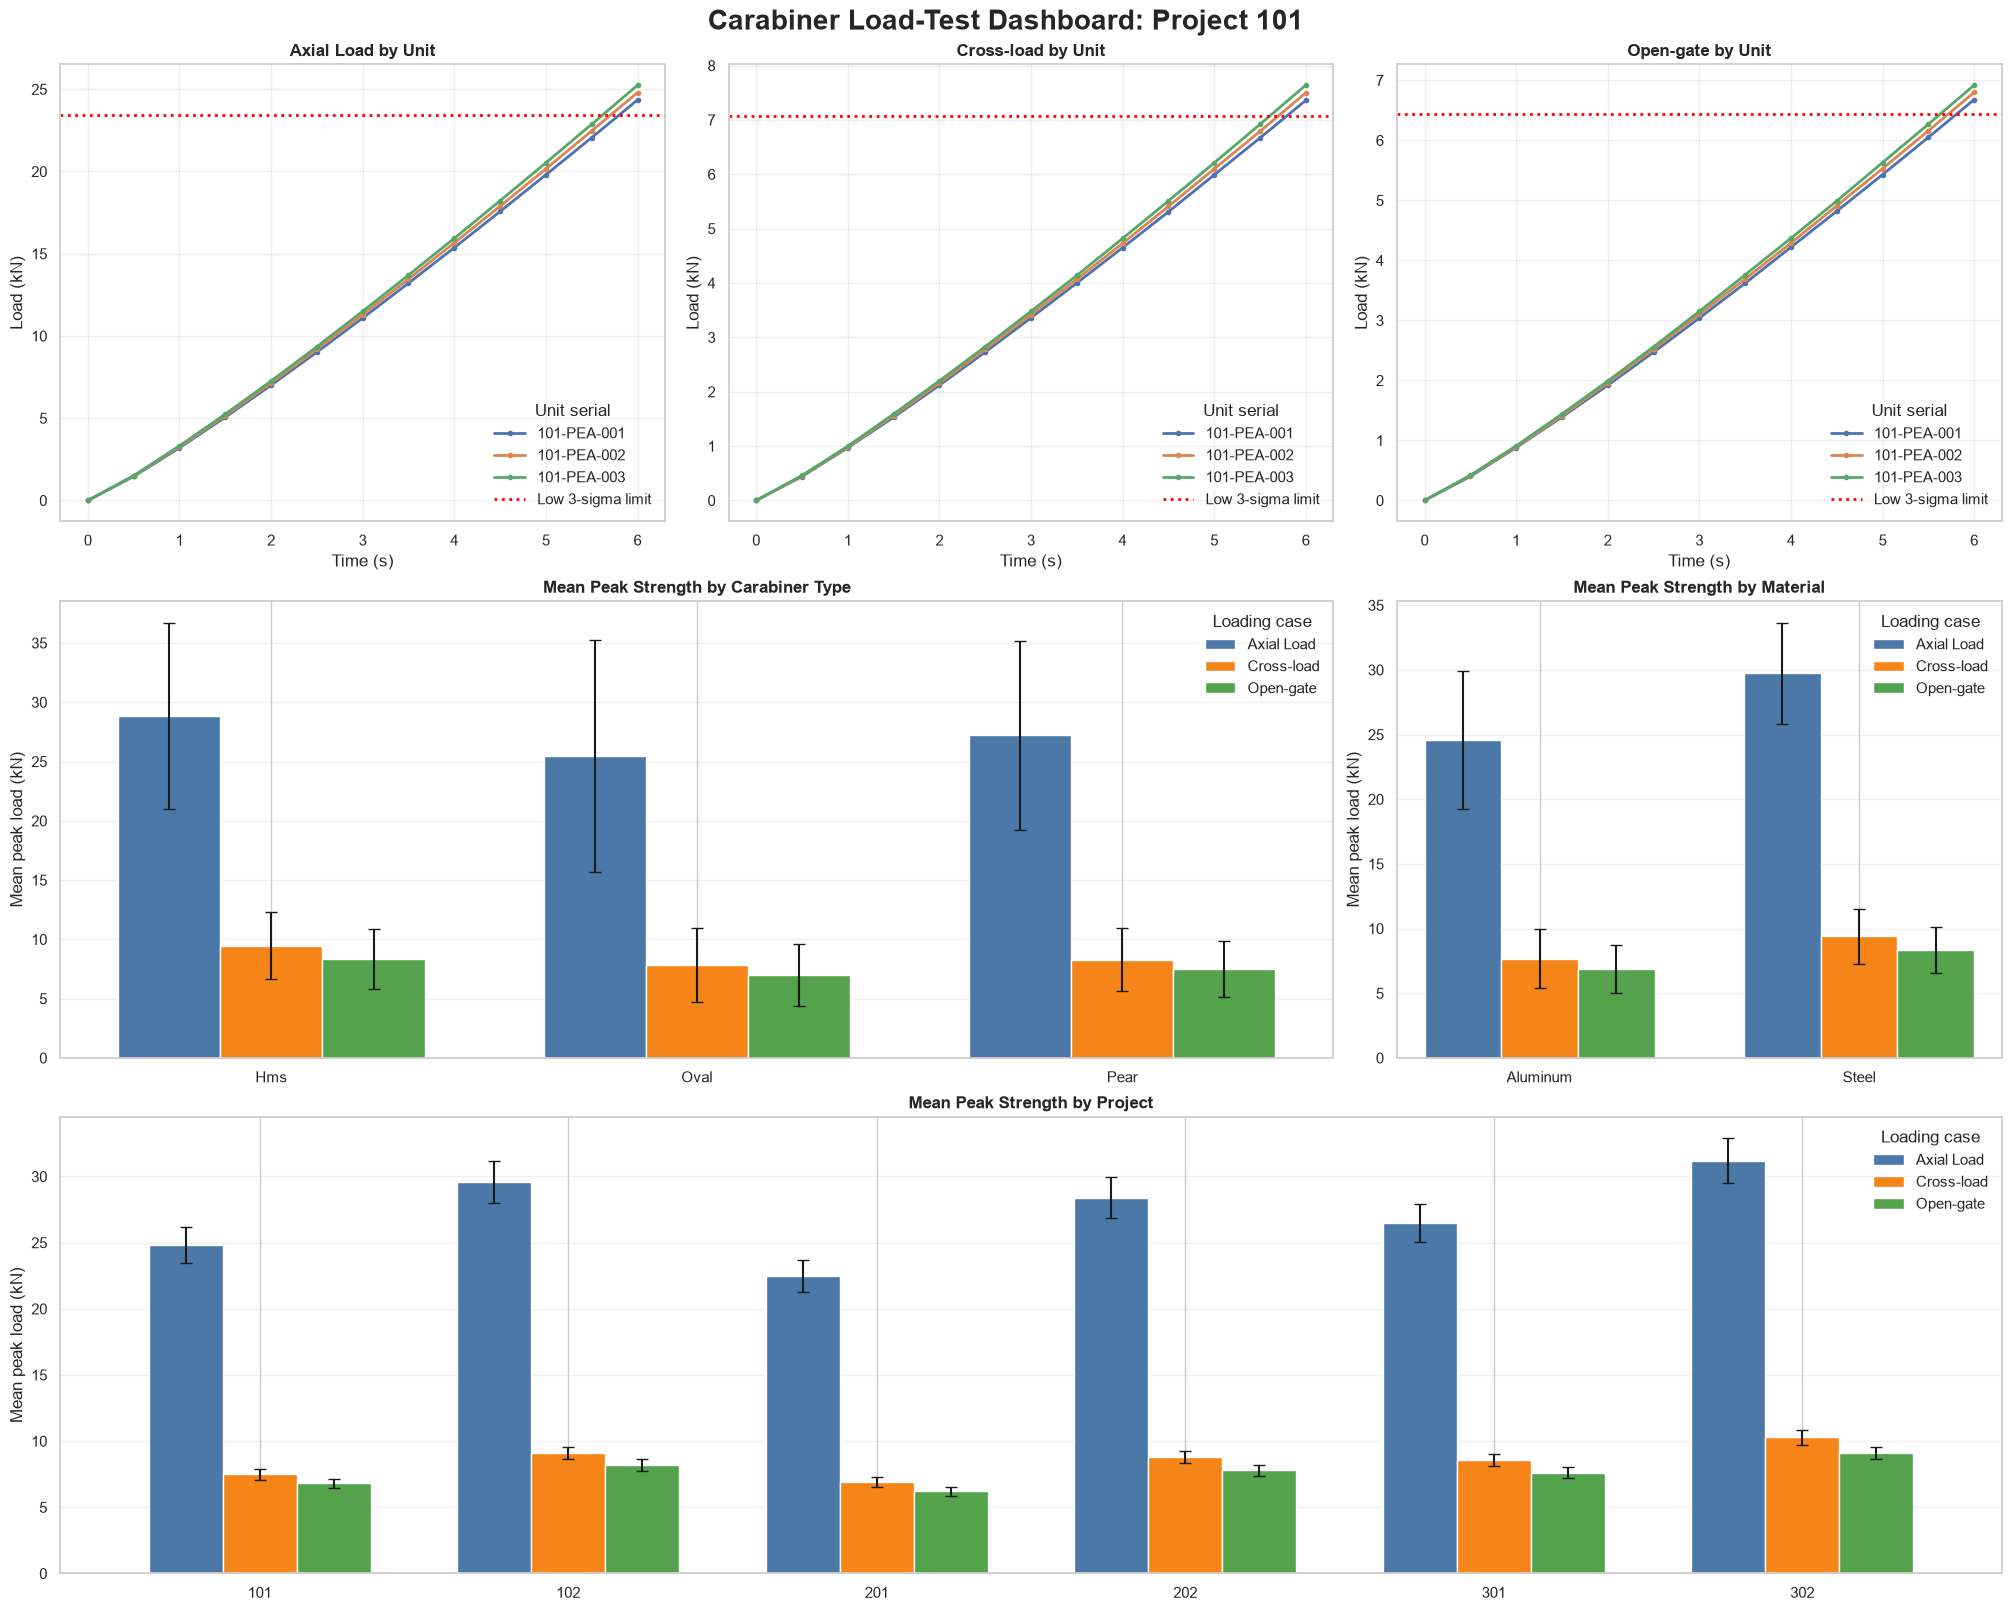

In [5]:
dashboard = LoadTestDashboard(testruns)
fig, dashboard_statistics = dashboard.plot_dashboard(project_code="101")
dashboard_statistics["project_limits"]